In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load dataset
data = load_breast_cancer()

# Convert into DataFrame
df = pd.DataFrame(data.data, columns=data.feature_names)

# Add target column
df['target'] = data.target

# Display first 5 rows
print(df.head())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

In [3]:
# Dataset information
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nTarget Distribution:")
print(df['target'].value_counts())

Dataset Shape: (569, 31)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-

In [4]:
# Independent variables
X = df.drop('target', axis=1)

# Dependent variable
y = df['target']

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

Input Shape: (569, 30)
Output Shape: (569,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (455, 30)
Testing data: (114, 30)


In [6]:
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    random_state=42
)

# Train model
bagging_model.fit(X_train, y_train)

# Predict
bagging_pred = bagging_model.predict(X_test)

print("Bagging Classification Completed!")

Bagging Classification Completed!


In [7]:
boosting_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

# Train model
boosting_model.fit(X_train, y_train)

# Predict
boosting_pred = boosting_model.predict(X_test)

print("Boosting Classification Completed!")

Boosting Classification Completed!


In [8]:
# Function to calculate performance
def evaluate_model(y_test, predictions, model_name):
    return {
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1 Score': f1_score(y_test, predictions)
    }

# Evaluate both models
results = []

results.append(
    evaluate_model(y_test, bagging_pred, "Bagging")
)

results.append(
    evaluate_model(y_test, boosting_pred, "Boosting")
)

# Display comparison
results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

   Model  Accuracy  Precision   Recall  F1 Score
 Bagging  0.938596   0.945205 0.958333  0.951724
Boosting  0.956140   0.946667 0.986111  0.965986


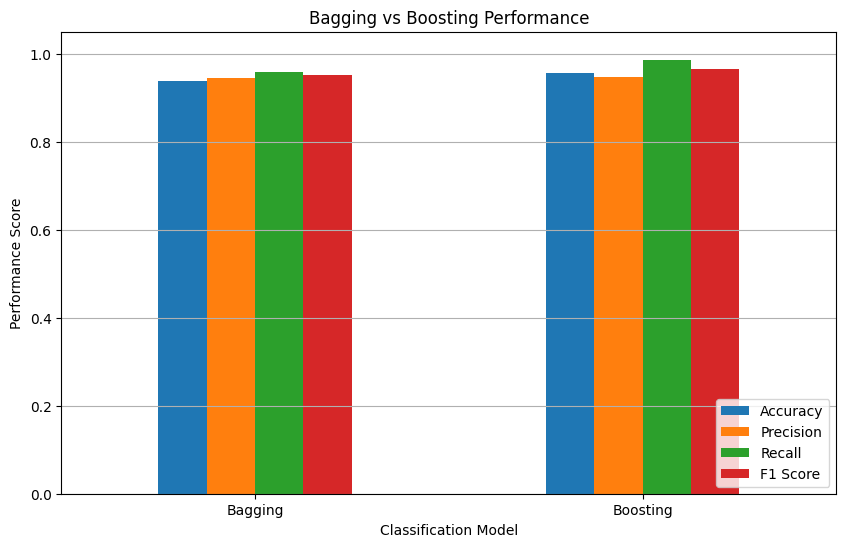

In [9]:
results_df.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Bagging vs Boosting Performance')
plt.ylabel('Performance Score')
plt.xlabel('Classification Model')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y')
plt.show()

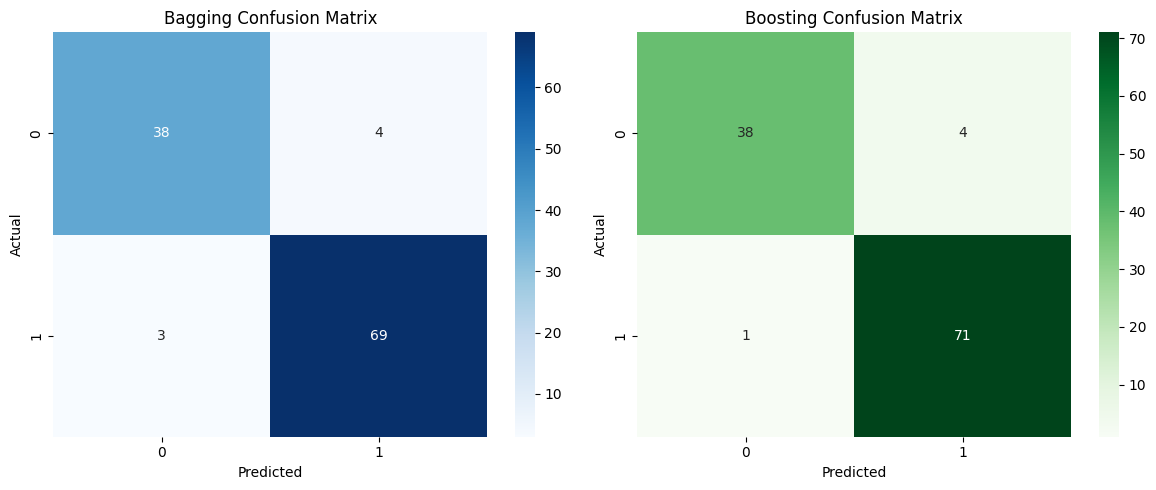

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bagging confusion matrix
sns.heatmap(
    confusion_matrix(y_test, bagging_pred),
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0]
)
axes[0].set_title('Bagging Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Boosting confusion matrix
sns.heatmap(
    confusion_matrix(y_test, boosting_pred),
    annot=True,
    fmt='d',
    cmap='Greens',
    ax=axes[1]
)
axes[1].set_title('Boosting Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [11]:
print("BAGGING CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    bagging_pred,
    target_names=data.target_names
))

print("\nBOOSTING CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    boosting_pred,
    target_names=data.target_names
))

BAGGING CLASSIFICATION REPORT
              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114


BOOSTING CLASSIFICATION REPORT
              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [12]:
best_model = results_df.loc[
    results_df['Accuracy'].idxmax()
]

print("Best Performing Model:")
print(best_model)

Best Performing Model:
Model        Boosting
Accuracy      0.95614
Precision    0.946667
Recall       0.986111
F1 Score     0.965986
Name: 1, dtype: object
